# 11 · Web 后端实战（自己完成）


来源：[飞书讲义《11-后端Web实战(自己完成)》](https://heuqqdmbyk.feishu.cn/wiki/NRjLwaRqDiEiFVkHLWGct6zFnNg)。整理日期：2026-09-29。

本章是独立实战任务，依讲义顺序保留 111 个内容块、3 段原代码和 16 张配图；其中包含 `clazz`、`student` 的建表和测试数据、两个实体类，以及班级/学员/统计接口任务。勘误与实现边界在原文旁标注，课程推广内容未收录。

讲义要求所有接口以配套接口文档为准；本笔记不臆造其中未列出的路径、请求字段或响应结构。SQL 应在数据库客户端执行，Java 代码应在 Spring Boot 项目中运行，Notebook 的 Python 内核不执行这些片段。


## 本章跟练路线（补充）

把前几章的分层、分页、动态 SQL、事务和全局异常处理组合起来，完成班级和学员两个资源的管理。建议每个接口完成后都先用接口文档测试，再交给前端联调。

| 顺序 | 目标 | 复用的前置知识 | 完成标准 |
| --- | --- | --- | --- |
| 1 | 导入并核对数据 | DDL、约束、实体映射 | 表、实体类和字段类型一致 |
| 2 | 班级管理 | 分页查询、动态条件、CRUD | 列表能显示班主任和派生状态 |
| 3 | 学员管理 | 分页查询、CRUD、关联查询 | 列表能显示班级名称并支持回显 |
| 4 | 违纪处理 | 参数校验、原子更新 | 次数与扣分正确累加 |
| 5 | 信息统计 | `GROUP BY`、图表数据结构 | 班级人数和学历分布可直接渲染 |
| 6 | 规则完善 | 自定义异常、事务 | 有关联数据时删除被拒绝并返回统一错误 |

本章没有提供 Controller、Service、Mapper 的完整答案，重点是按接口文档独立完成，并复盘每个接口在三层中的职责。


<strong>注意：所有的接口在开发时，一定一定一定 </strong><strong>要按照接口文档开发。</strong><strong> 否则，和前端进行联调时，将会出现问题。</strong>

<strong>注意：所有的接口在开发时，一定一定一定 要按照接口文档开发。 否则，和前端进行联调时，将会出现问题。</strong>

<strong>注意：所有的接口在开发时，一定一定一定 要按照接口文档开发。 否则，和前端进行联调时，将会出现问题。</strong>


## 1 数据准备

在数据库中，创建学生表 <code>clazz</code> , <code>student</code>，SQL如下：

**勘误｜表名。** 此处“学生表 clazz , student”应为“创建 `clazz`（班级表）和 `student`（学员表）”。实体类字段与数据库列名的驼峰映射要保持一致，例如 `begin_date` → `beginDate`。

````sql
create table clazz(
    id   int unsigned primary key auto_increment comment 'ID,主键',
    name  varchar(30) not null unique  comment '班级名称',
    room  varchar(20) comment '班级教室',
    begin_date date not null comment '开课时间',
    end_date date not null comment '结课时间',
    master_id int unsigned null comment '班主任ID, 关联员工表ID',
    subject tinyint unsigned not null comment '学科, 1:java, 2:前端, 3:大数据, 4:Python, 5:Go, 6: 嵌入式',
    create_time datetime  comment '创建时间',
    update_time datetime  comment '修改时间'
)comment '班级表';

INSERT INTO clazz VALUES (1,'JavaEE就业163期','212','2024-04-30','2024-06-29',10,1,'2024-06-01 17:08:23','2024-06-01 17:39:58'),
    (2,'前端就业90期','210','2024-07-10','2024-01-20',3,2,'2024-06-01 17:45:12','2024-06-01 17:45:12'),
    (3,'JavaEE就业165期','108','2024-06-15','2024-12-25',6,1,'2024-06-01 17:45:40','2024-06-01 17:45:40'),
    (4,'JavaEE就业166期','105','2024-07-20','2024-02-20',20,1,'2024-06-01 17:46:10','2024-06-01 17:46:10'),
    (5,'大数据就业58期','209','2024-08-01','2024-02-15',7,3,'2024-06-01 17:51:21','2024-06-01 17:51:21'),
    (6,'JavaEE就业167期','325','2024-11-20','2024-05-10',36,1,'2024-11-15 11:35:46','2024-12-13 14:31:24');


create table student(
  id int unsigned primary key auto_increment comment 'ID,主键',
  name varchar(10)  not null comment '姓名',
  no char(10)  not null unique comment '学号',
  gender tinyint unsigned  not null comment '性别, 1: 男, 2: 女',
  phone  varchar(11)  not null unique comment '手机号',
  id_card  char(18)  not null unique comment '身份证号',
  is_college tinyint unsigned  not null comment '是否来自于院校, 1:是, 0:否',
  address  varchar(100)  comment '联系地址',
  degree  tinyint unsigned  comment '最高学历, 1:初中, 2:高中, 3:大专, 4:本科, 5:硕士, 6:博士',
  graduation_date date comment '毕业时间',
  clazz_id  int unsigned not null comment '班级ID, 关联班级表ID',
  violation_count tinyint unsigned default '0' not null comment '违纪次数',
  violation_score tinyint unsigned default '0' not null comment '违纪扣分',
  create_time  datetime  comment '创建时间',
  update_time  datetime  comment '修改时间'
) comment '学员表';


INSERT INTO student VALUES (1,'段誉','2022000001',1,'18800000001','110120000300200001',1,'北京市昌平区建材城西路1号',1,'2021-07-01',2,0,0,'2024-11-14 21:22:19','2024-11-15 16:20:59'),
    (2,'萧峰','2022000002',1,'18800210003','110120000300200002',1,'北京市昌平区建材城西路2号',2,'2022-07-01',1,0,0,'2024-11-14 21:22:19','2024-11-14 21:22:19'),
    (3,'虚竹','2022000003',1,'18800013001','110120000300200003',1,'北京市昌平区建材城西路3号',2,'2024-07-01',1,0,0,'2024-11-14 21:22:19','2024-11-14 21:22:19'),
    (4,'萧远山','2022000004',1,'18800003211','110120000300200004',1,'北京市昌平区建材城西路4号',3,'2024-07-01',1,0,0,'2024-11-14 21:22:19','2024-11-14 21:22:19'),
    (5,'阿朱','2022000005',2,'18800160002','110120000300200005',1,'北京市昌平区建材城西路5号',4,'2020-07-01',1,0,0,'2024-11-14 21:22:19','2024-11-14 21:22:19'),
    (6,'阿紫','2022000006',2,'18800000034','110120000300200006',1,'北京市昌平区建材城西路6号',4,'2021-07-01',2,0,0,'2024-11-14 21:22:19','2024-11-14 21:22:19'),
    (7,'游坦之','2022000007',1,'18800000067','110120000300200007',1,'北京市昌平区建材城西路7号',4,'2022-07-01',2,0,0,'2024-11-14 21:22:19','2024-11-14 21:22:19'),
    (8,'康敏','2022000008',2,'18800000077','110120000300200008',1,'北京市昌平区建材城西路8号',5,'2024-07-01',2,0,0,'2024-11-14 21:22:19','2024-11-14 21:22:19'),
    (9,'徐长老','2022000009',1,'18800000341','110120000300200009',1,'北京市昌平区建材城西路9号',3,'2024-07-01',2,0,0,'2024-11-14 21:22:19','2024-11-14 21:22:19'),
    (10,'云中鹤','2022000010',1,'18800006571','110120000300200010',1,'北京市昌平区建材城西路10号',2,'2020-07-01',2,0,0,'2024-11-14 21:22:19','2024-11-14 21:22:19'),
    (11,'钟万仇','2022000011',1,'18800000391','110120000300200011',1,'北京市昌平区建材城西路11号',4,'2021-07-01',1,0,0,'2024-11-14 21:22:19','2024-11-15 16:21:24'),
    (12,'崔百泉','2022000012',1,'18800000781','110120000300200018',1,'北京市昌平区建材城西路12号',4,'2022-07-05',3,6,17,'2024-11-14 21:22:19','2024-12-13 14:33:58'),
    (13,'耶律洪基','2022000013',1,'18800008901','110120000300200013',1,'北京市昌平区建材城西路13号',4,'2024-07-01',2,0,0,'2024-11-14 21:22:19','2024-11-15 16:21:21'),
    (14,'天山童姥','2022000014',2,'18800009201','110120000300200014',1,'北京市昌平区建材城西路14号',4,'2024-07-01',1,0,0,'2024-11-14 21:22:19','2024-11-15 16:21:17'),
    (15,'刘竹庄','2022000015',1,'18800009401','110120000300200015',1,'北京市昌平区建材城西路15号',3,'2020-07-01',4,0,0,'2024-11-14 21:22:19','2024-11-14 21:22:19'),
    (16,'李春来','2022000016',1,'18800008501','110120000300200016',1,'北京市昌平区建材城西路16号',4,'2021-07-01',4,0,0,'2024-11-14 21:22:19','2024-11-14 21:22:19'),
    (17,'王语嫣','2022000017',2,'18800007601','110120000300200017',1,'北京市昌平区建材城西路17号',2,'2022-07-01',4,0,0,'2024-11-14 21:22:19','2024-11-14 21:22:19'),
    (18,'郑成功','2024001101',1,'13309092345','110110110110110110',0,'北京市昌平区回龙观街道88号',5,'2021-07-01',3,2,7,'2024-11-15 16:26:18','2024-11-15 16:40:10');
````

**补充｜样例数据检查。** 建表语句只用注释描述关联关系，未定义外键；实际项目至少应为 `student.clazz_id`、`clazz.master_id` 建索引，并明确删除策略。样例中的多条班级记录出现开课日期晚于结课日期，导入前应修正；可在服务层校验 `beginDate` 不晚于 `endDate`。学员表含身份证号、手机号等敏感信息，接口响应应按最小必要原则脱敏或不返回。

表结构关系说明：

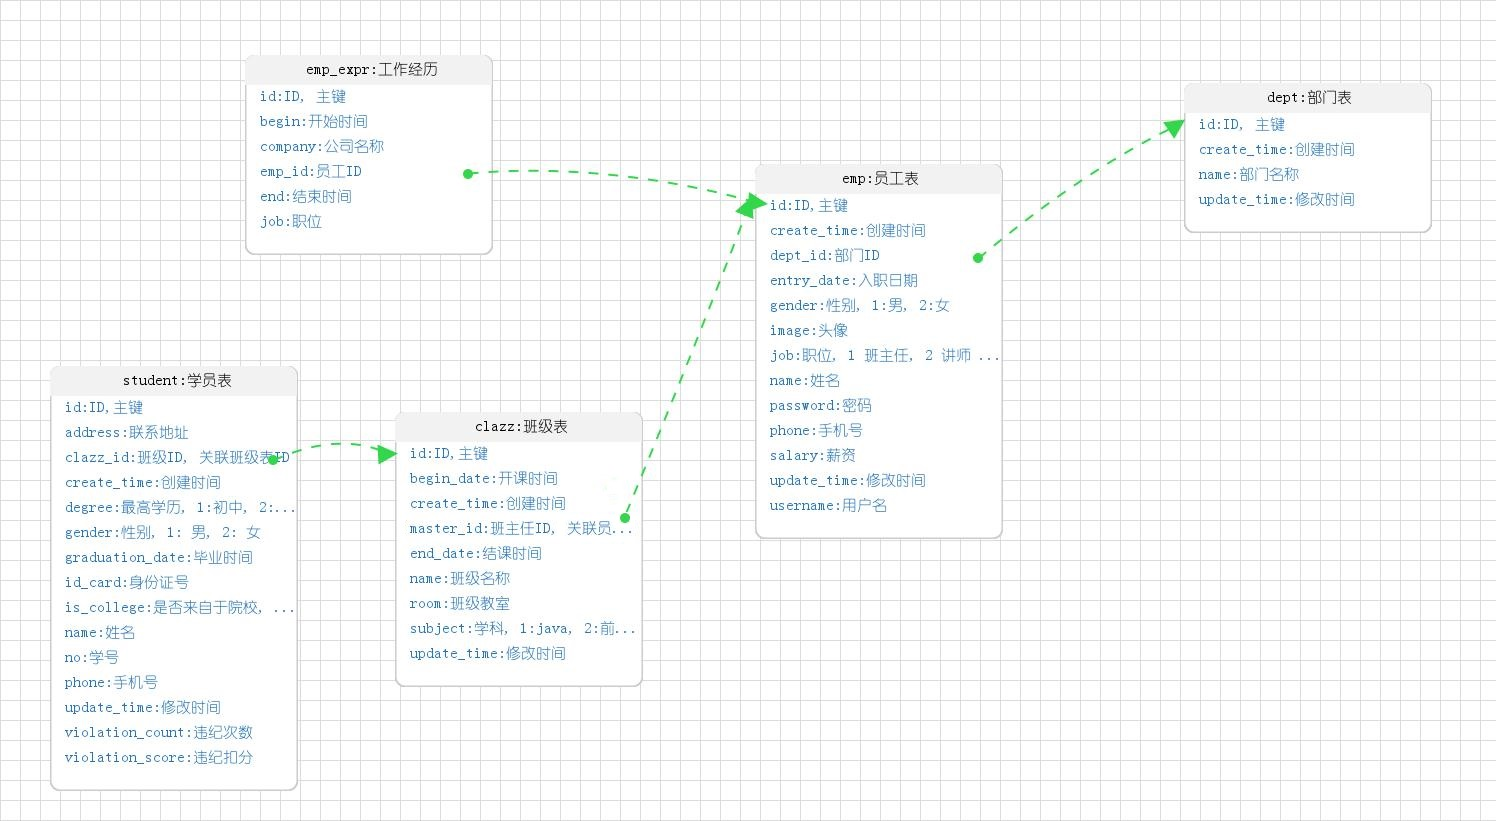

实体类Clazz：

````java
@Data
@NoArgsConstructor
@AllArgsConstructor
public class Clazz {
    private Integer id; //ID
    private String name; //班级名称
    private String room; //班级教室
    private LocalDate beginDate; //开课时间
    private LocalDate endDate; //结课时间
    private Integer masterId; //班主任
    private Integer subject; //学科
    private LocalDateTime createTime; //创建时间
    private LocalDateTime updateTime; //修改时间

    private String masterName; //班主任姓名
    private String status; //班级状态 - 未开班 , 在读 , 已结课
}
````

**补充｜派生字段。** `masterName` 和 `status` 不直接落在 `clazz` 表中，查询列表时需通过员工表连接获取班主任姓名，并根据当前日期与开、结课日期计算状态。状态计算应统一在 SQL 或服务层的一处完成，避免列表与详情口径不一致。

实体类Student：

````java
@Data
@NoArgsConstructor
@AllArgsConstructor
public class Student {
    private Integer id; //ID
    private String name; //姓名
    private String no; //序号
    private Integer gender; //性别 , 1: 男 , 2 : 女
    private String phone; //手机号
    private String idCard; //身份证号
    private Integer isCollege; //是否来自于院校, 1: 是, 0: 否
    private String address; //联系地址
    private Integer degree; //最高学历, 1: 初中, 2: 高中 , 3: 大专 , 4: 本科 , 5: 硕士 , 6: 博士
    private LocalDate graduationDate; //毕业时间
    private Integer clazzId; //班级ID
    private Short violationCount; //违纪次数
    private Short violationScore; //违纪扣分
    private LocalDateTime createTime; //创建时间
    private LocalDateTime updateTime; //修改时间

    private String clazzName;//班级名称
}
````

**补充｜数据边界。** `no` 是学号，保留为 `String` 是合理的，可避免前导零或非纯数字编号被错误转换。`idCard`、`phone` 不应写入日志，也不应在列表接口完整暴露；唯一约束冲突应交给全局异常处理器转换为可读的业务错误。


## 2 需求：班级管理

需要开发如下几个接口，且开发的时候建议按照如下顺序开发 ：


### 2.1 条件分页查询接口

参照接口文档 <strong><code>班级管理</code></strong> -&gt; <strong><code>班级列表查询</code></strong>

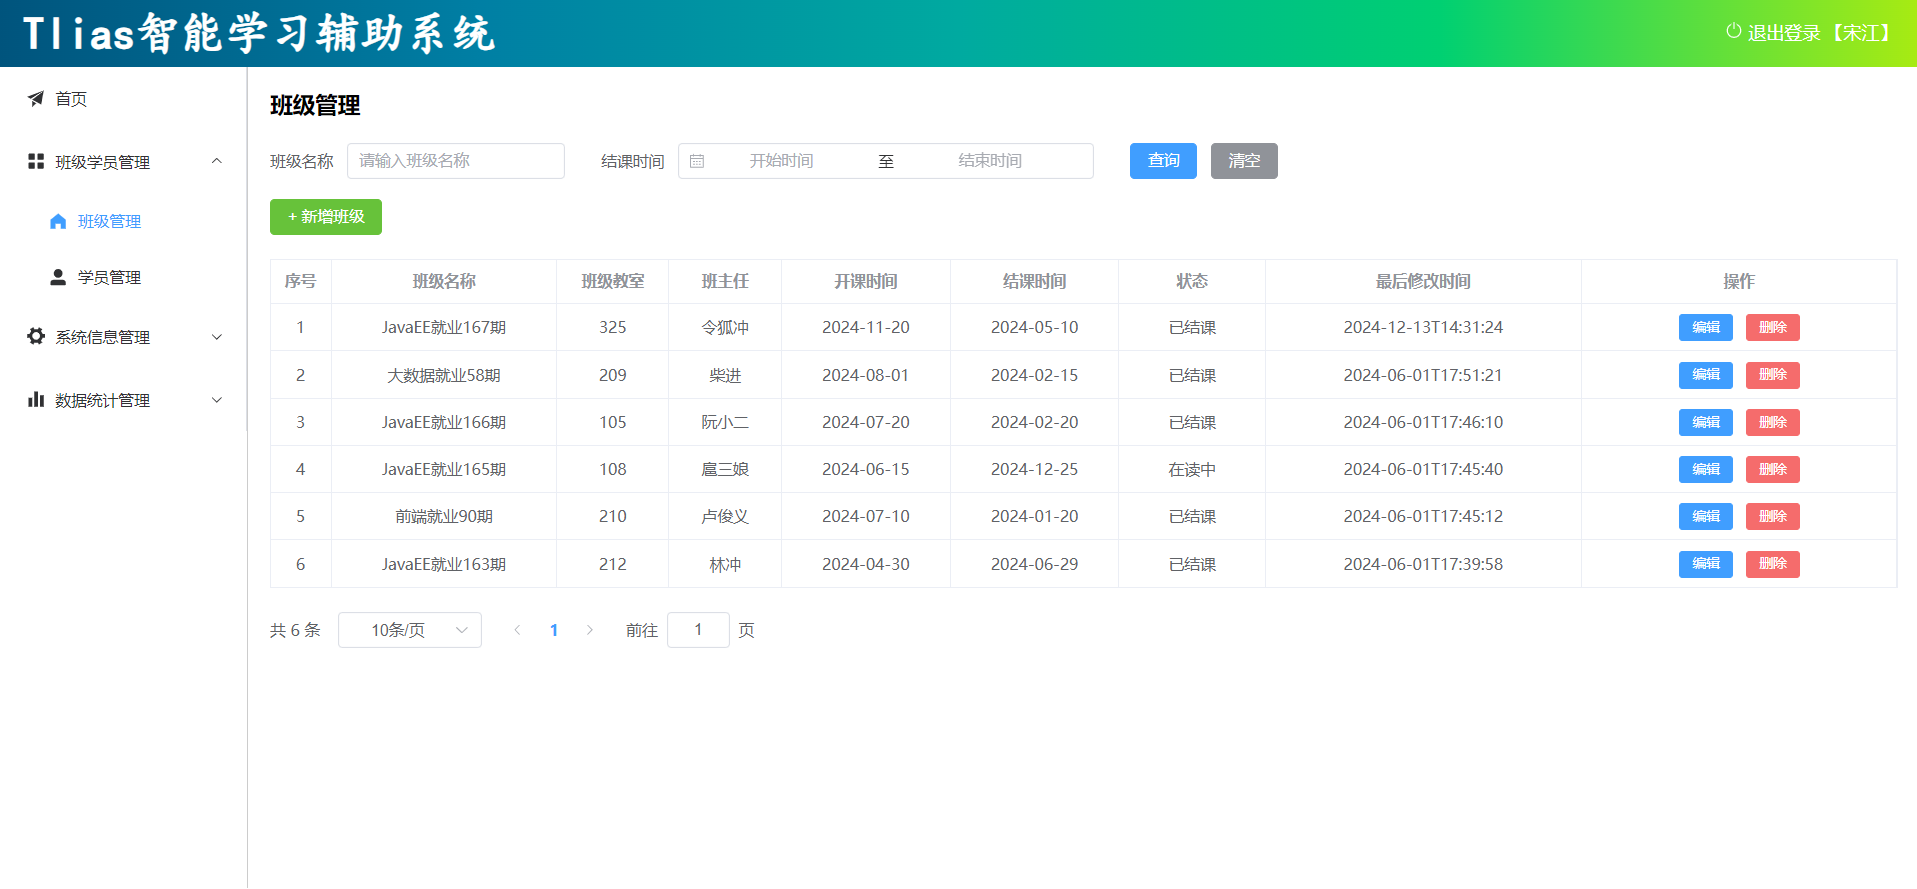

注意：班级状态，显示为：<strong>未开班、已结课、在读中</strong> 这三种。

如果：

- 当前时间 &gt; 结课时间：状态未 <strong>已结课</strong>。

**勘误｜状态文字。** “状态未 已结课”应为“状态为 已结课”。边界要明确：讲义使用 `>` / `<`，因此开课日和结课日当天归为“在读中”；实现时应统一时区和比较粒度。
- 当前时间 &lt; 开课时间：状态未 <strong>未开班</strong>。
- 否则，就是 <strong>在读中</strong>。


### 2.2 查询所有员工接口

那其实，对于培训机构来说，班主任就是这个企业的员工。所以，班主任下拉列表中展示的就是所有的员工数据。

参照接口文档 <strong><code>员工管理</code></strong> -&gt; <strong><code>查询全部员工</code></strong>

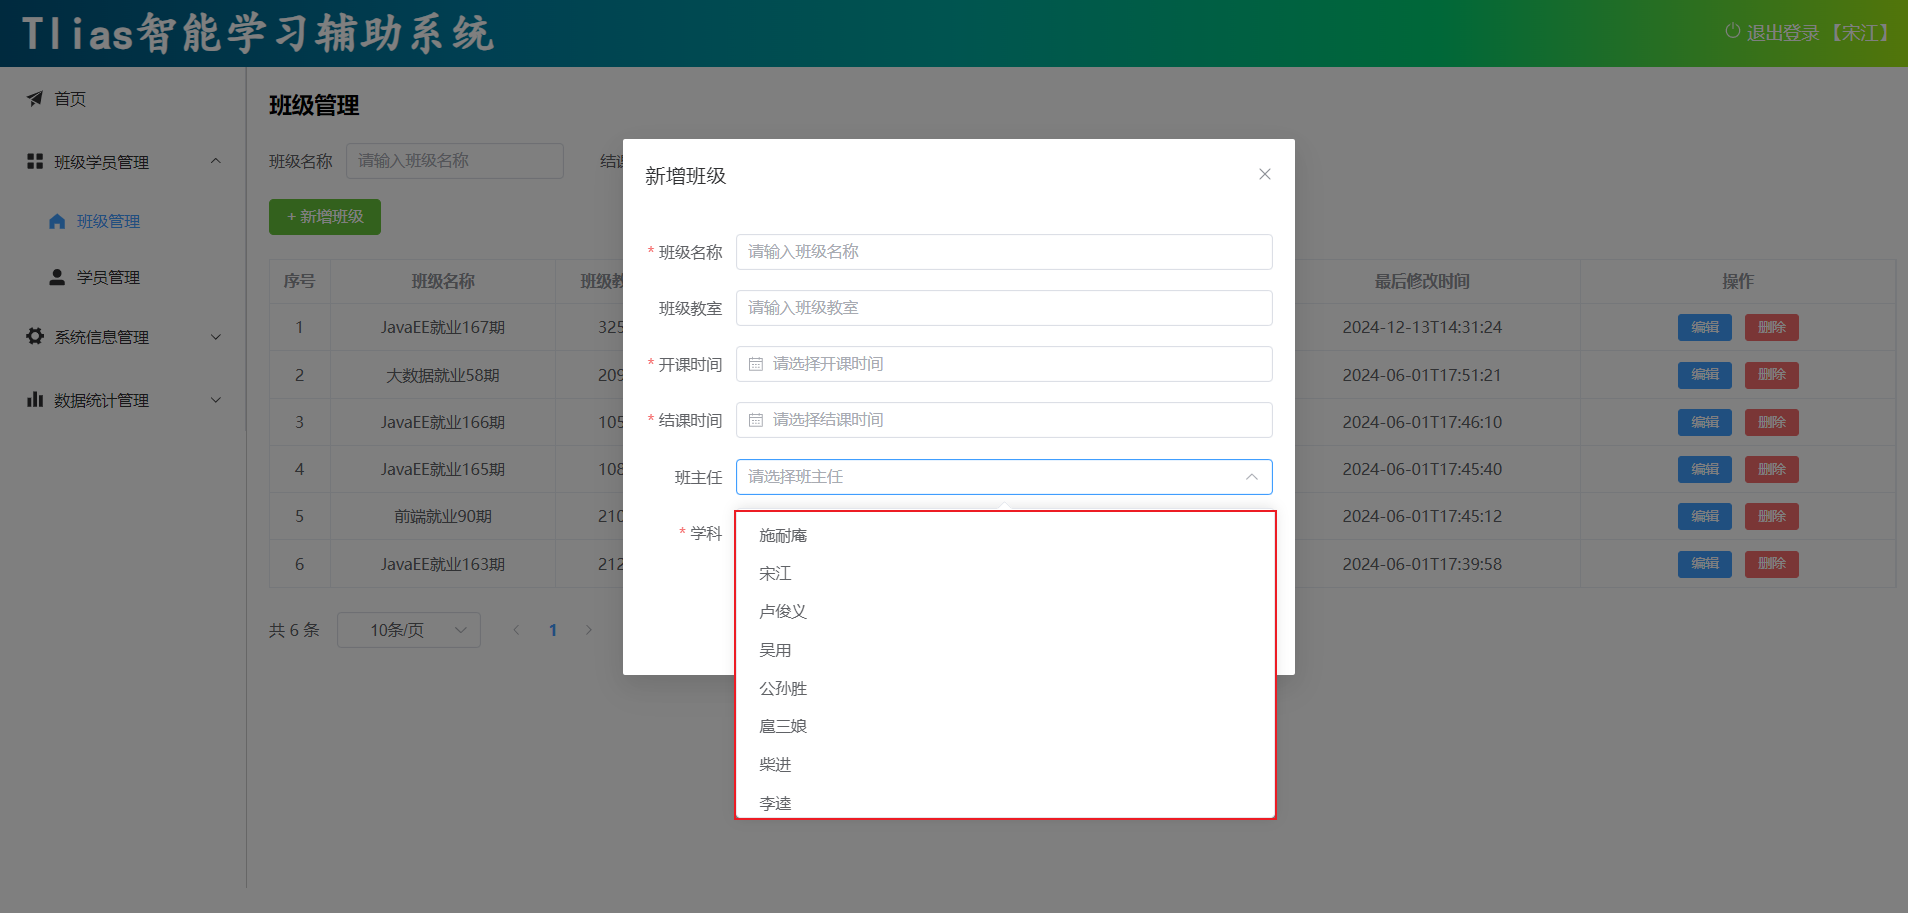


### 2.3 新增班级信息接口

参照接口文档 <strong><code>班级管理</code></strong> -&gt; <strong><code>添加班级</code></strong>

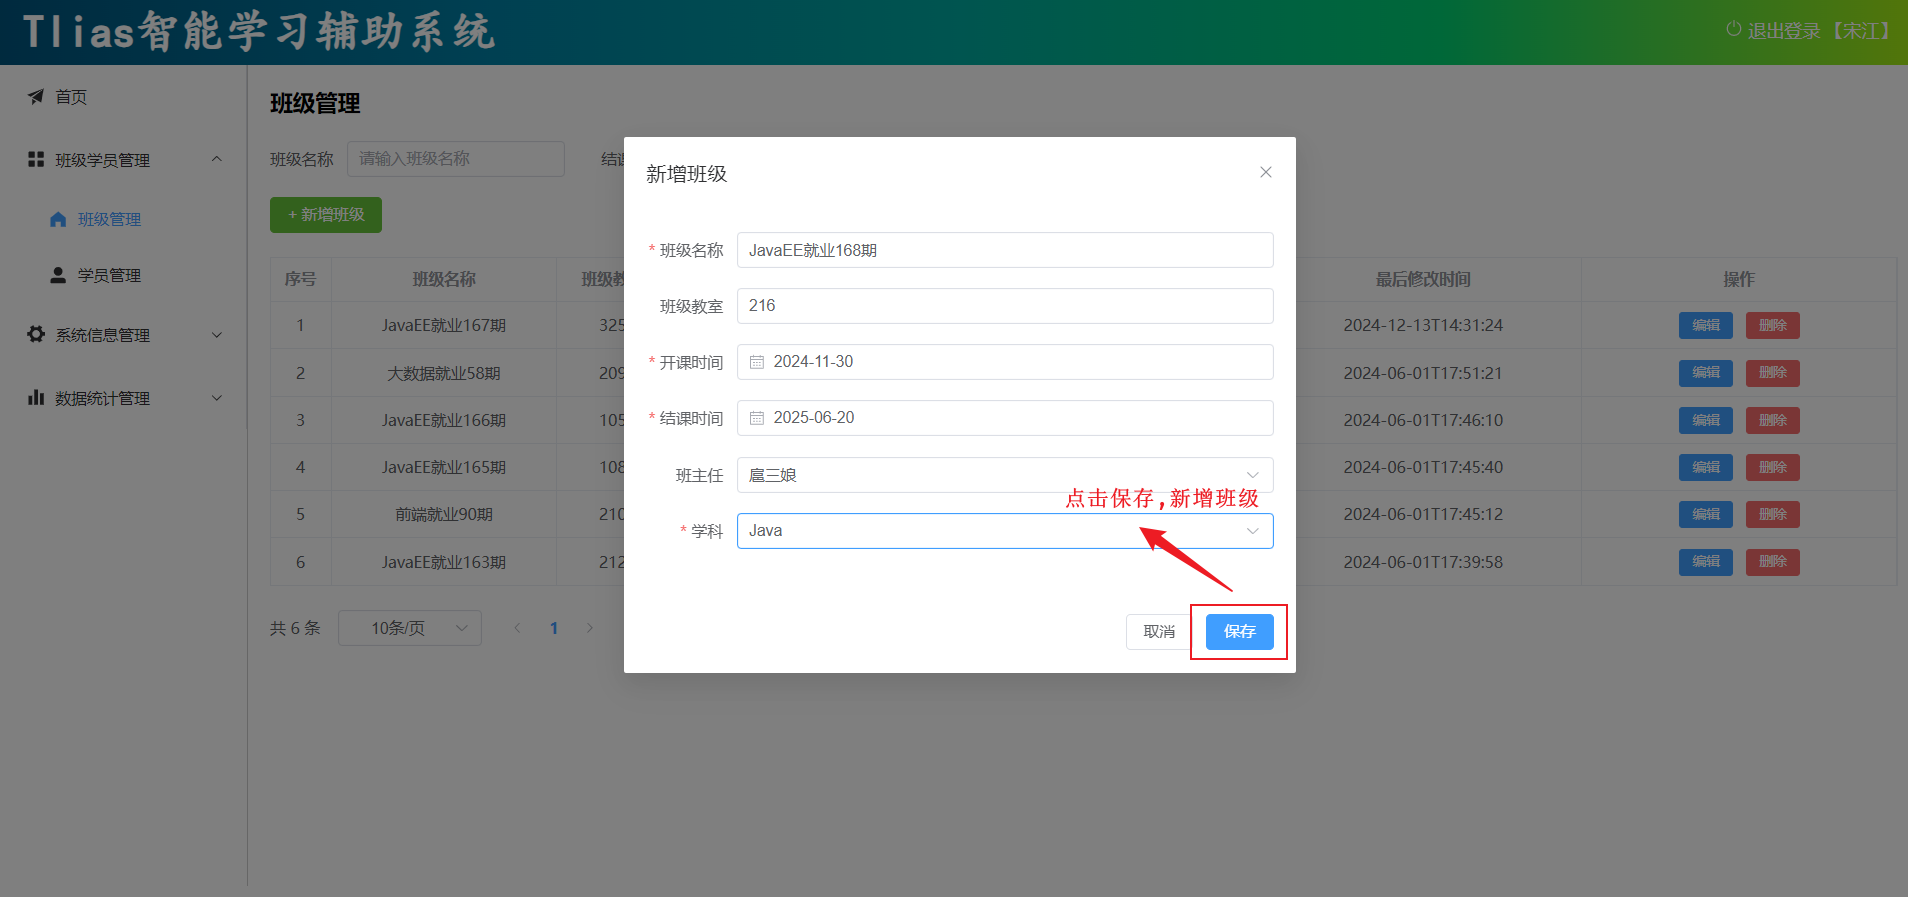


### 2.4 根据ID查询班级接口

参照接口文档 <strong><code>班级管理</code></strong> -&gt; <strong><code>根据ID查询</code></strong>

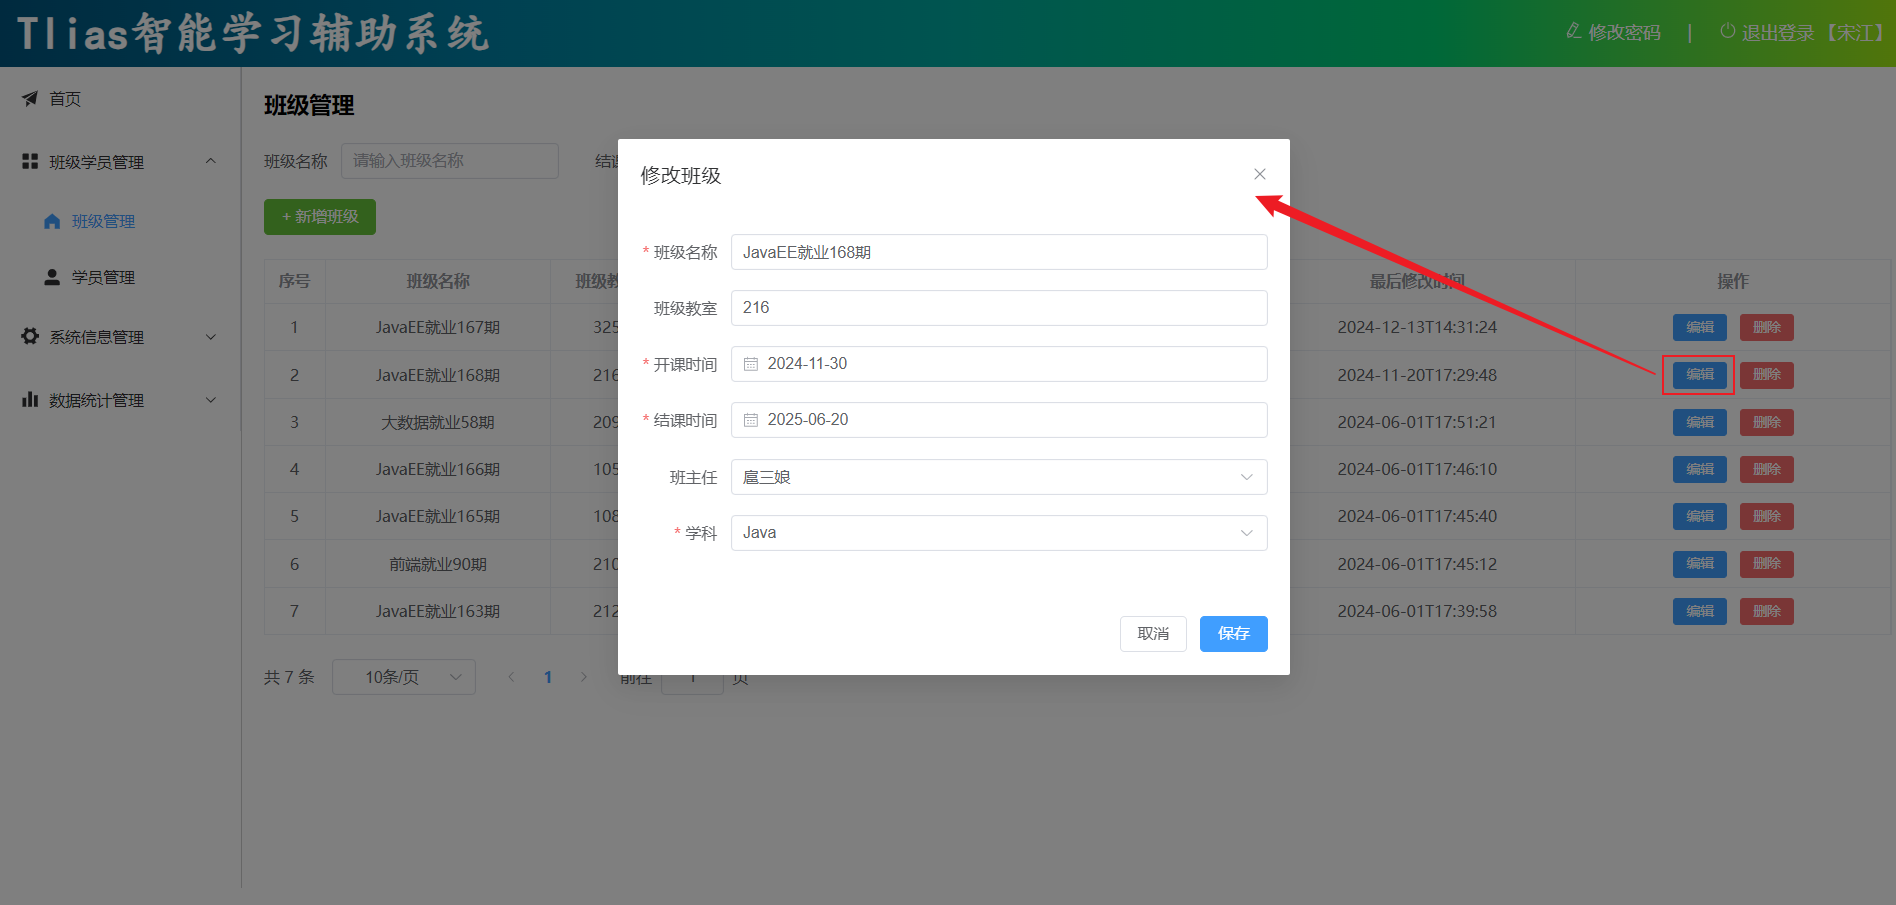


### 2.5 修改班级信息接口

参照接口文档 <strong><code>班级管理</code></strong> -&gt; <strong><code>修改班级</code></strong>

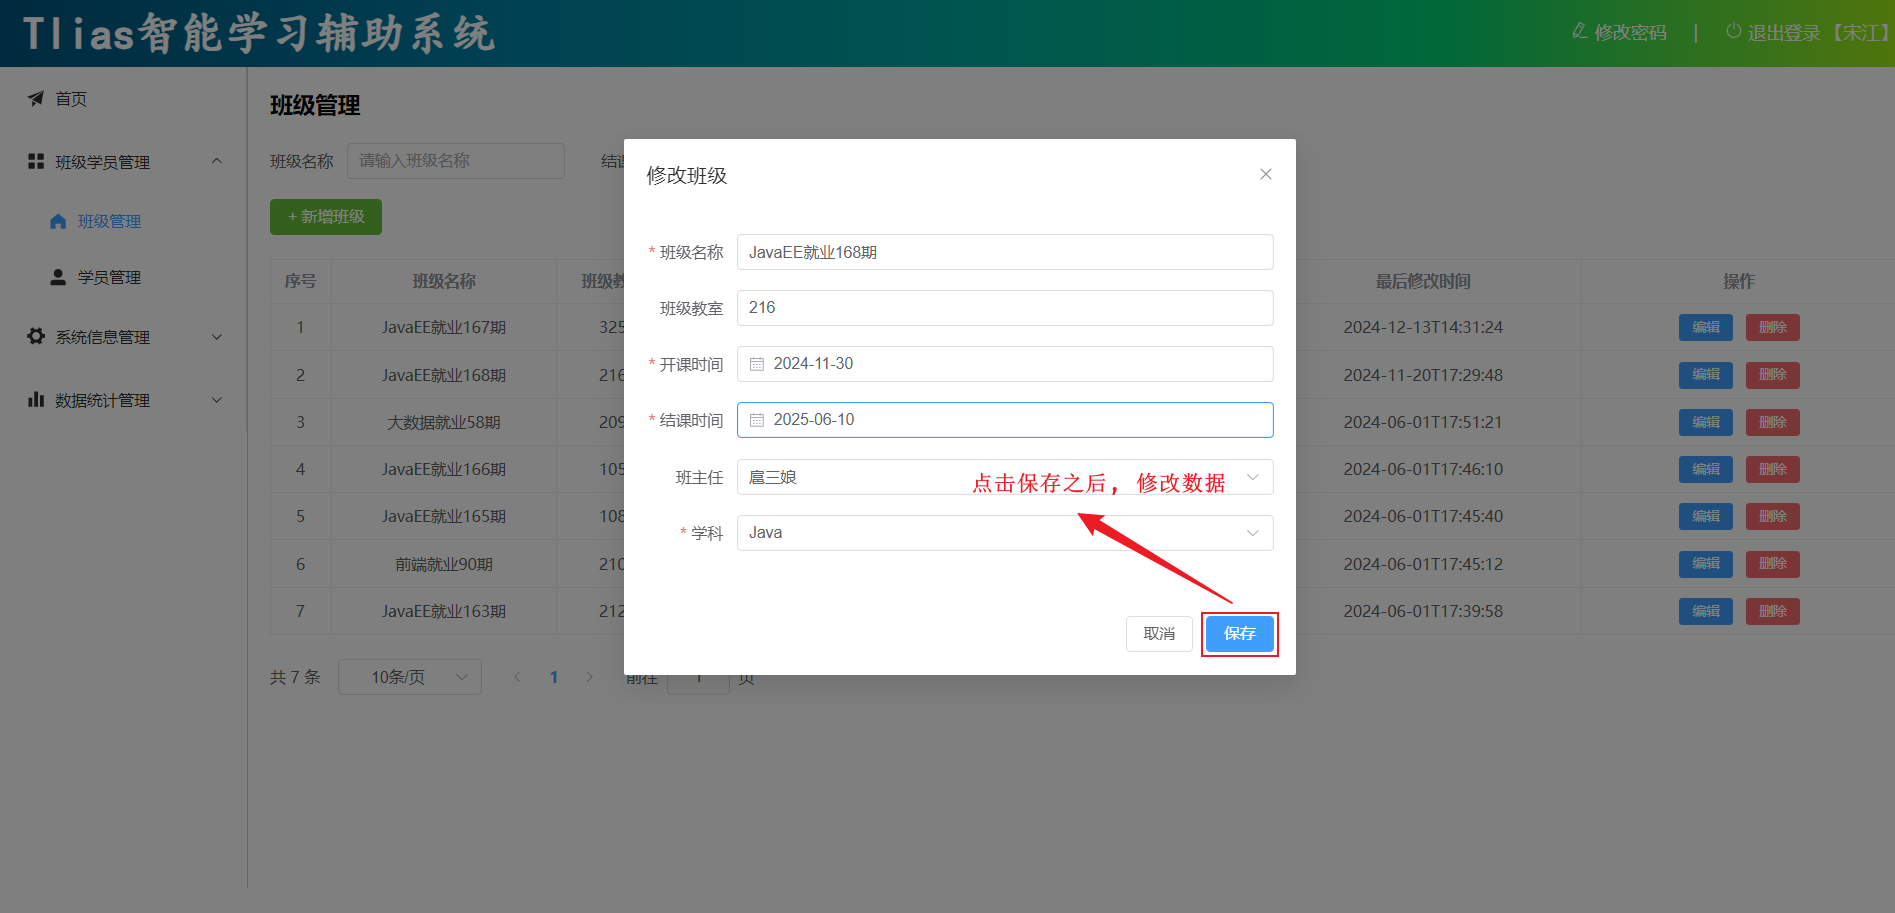


### 2.6 删除班级信息接口

参照接口文档 <strong><code>班级管理</code></strong> -&gt; <strong><code>删除班级</code></strong>

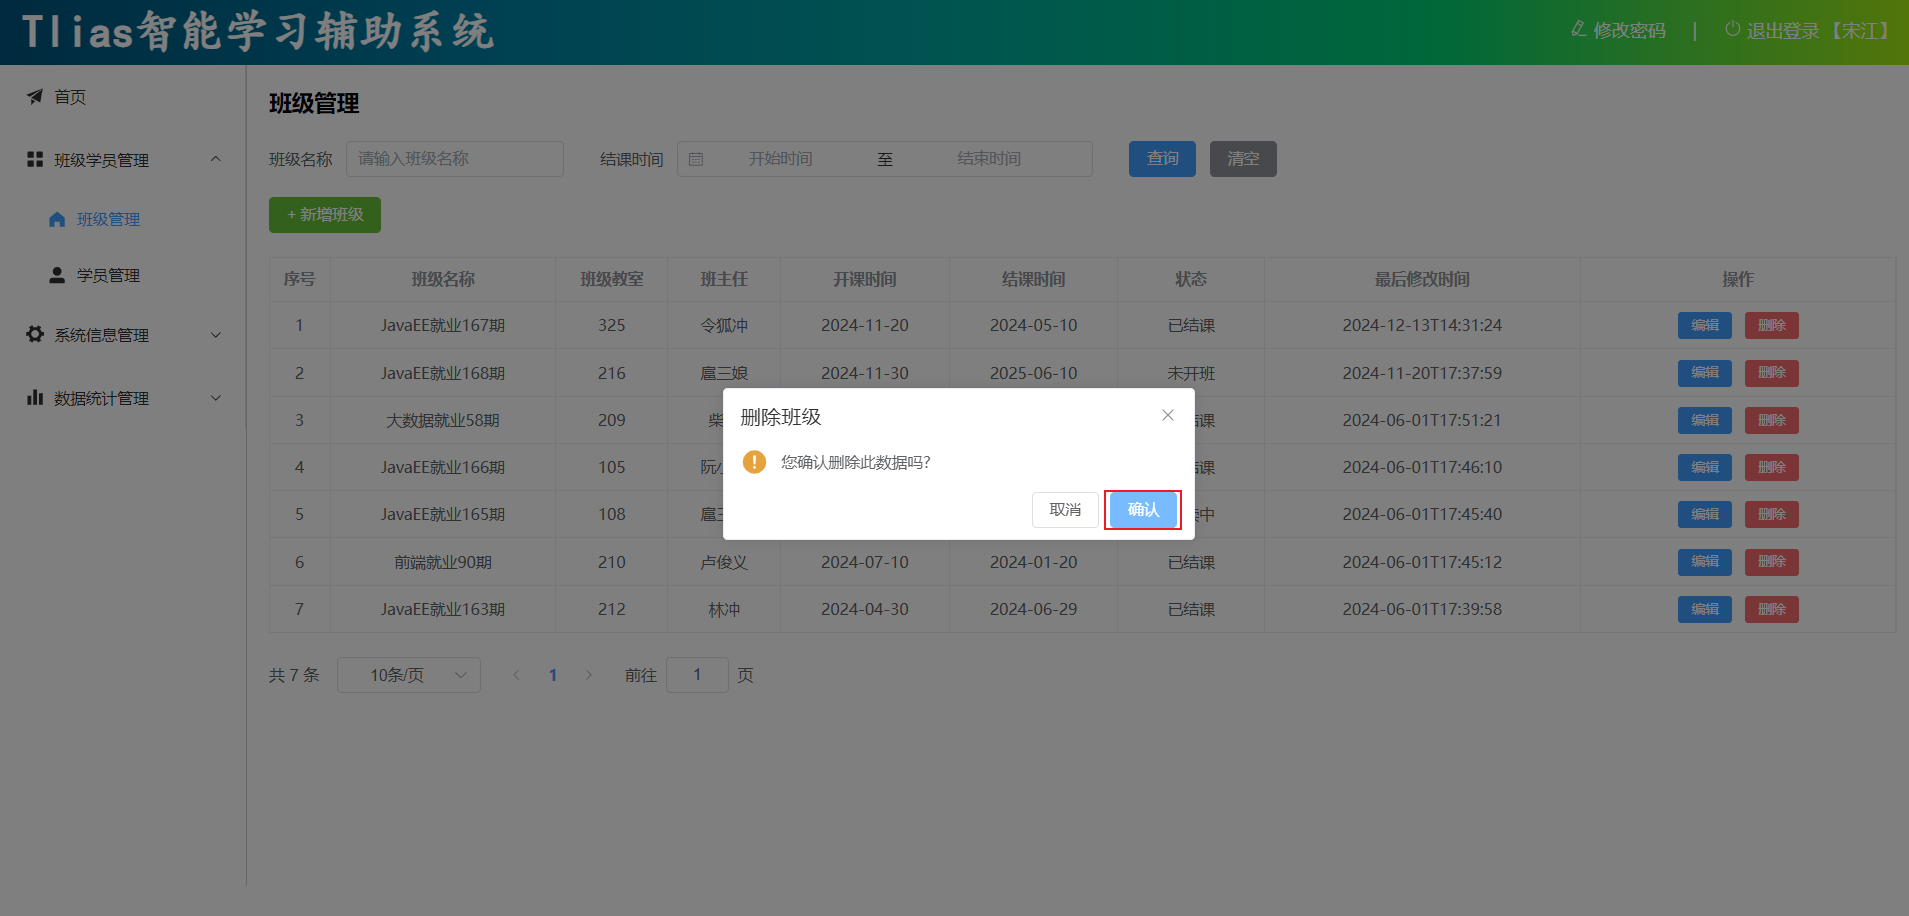

<strong>注意：在页面原型中，要求如果该班级下关联的有学生，是不允许删除的，并提示错误信息："对不起, 该班级下有学生, 不能直接删除"。 (提示：可以通过自定义异常 + 全局异常处理器实现)</strong>

**补充｜删除保护。** 删除班级前应先执行存在性检查或依赖数据库外键 `RESTRICT`，防止并发插入学员后留下孤儿记录。检查和删除建议放在同一事务中，并让自定义业务异常由全局异常处理器返回统一结果。

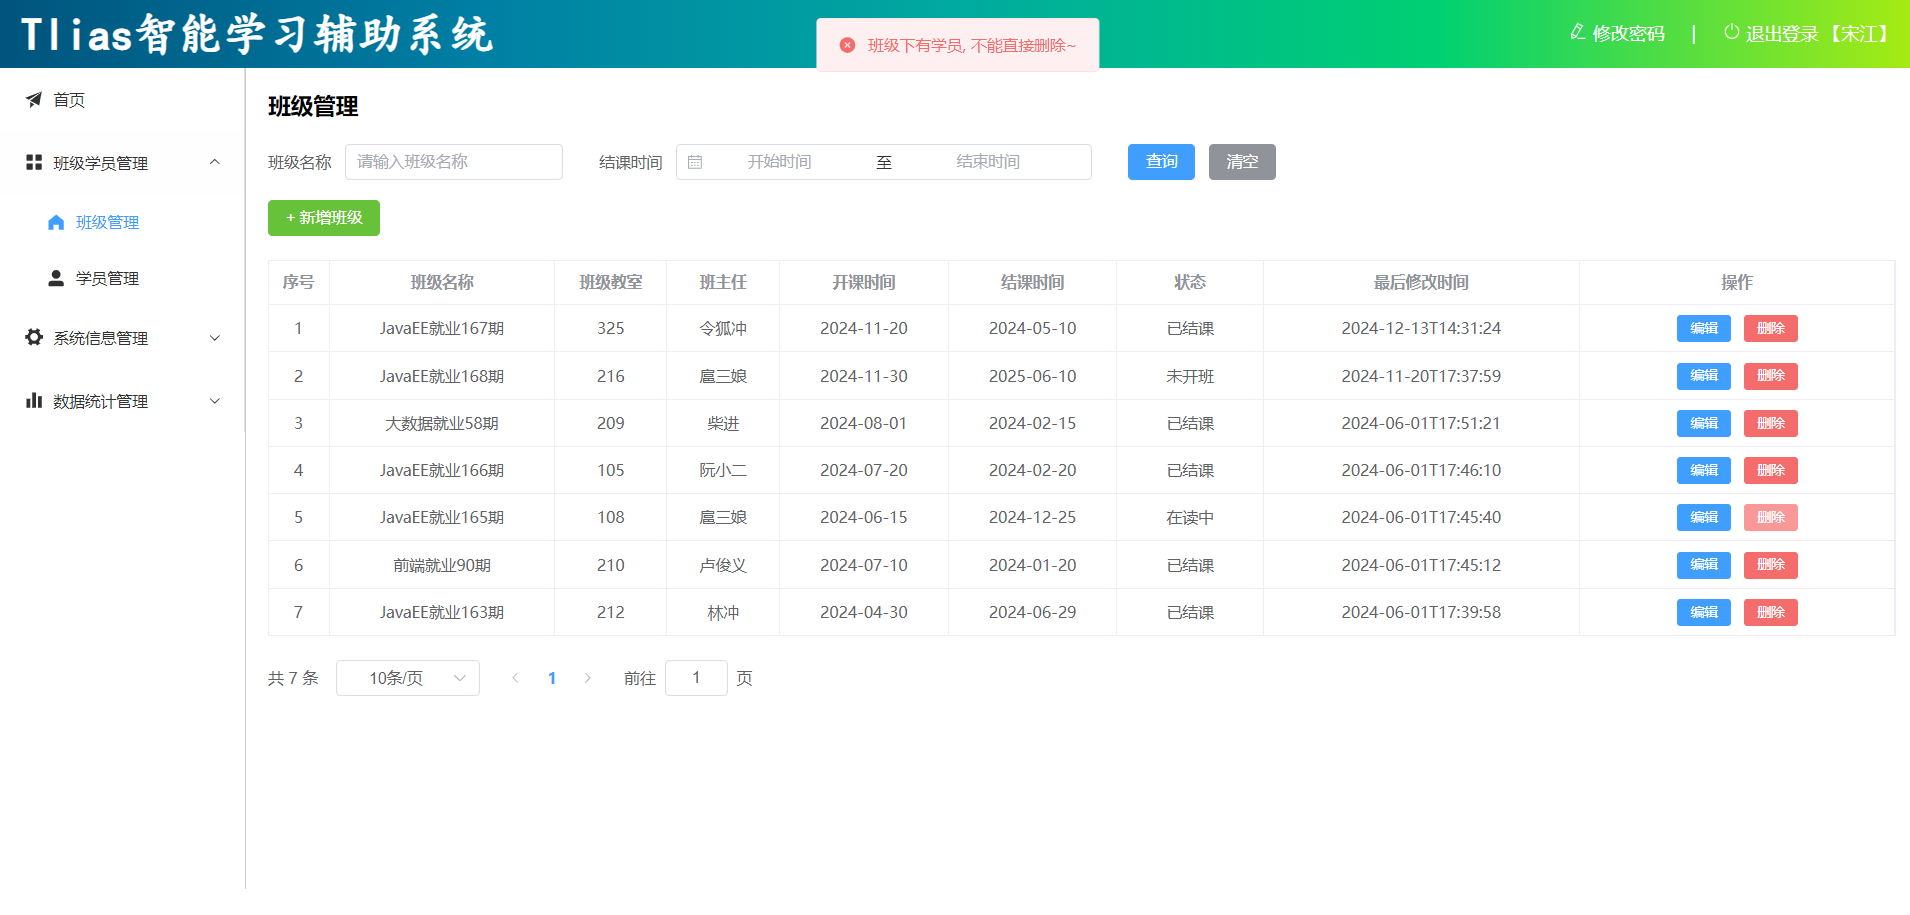

到此，关于班级管理的增删改查功能，我们就已经全部实现了。


## 3 需求：学员管理

需要开发如下几个接口，建议按照如下顺序开发接口：


### 3.1 查询所有班级接口

参照接口文档 <strong><code>班级管理</code></strong> -&gt; <strong><code>查询所有班级</code></strong>

在新增学员的时候，要展示出所有的班级信息。

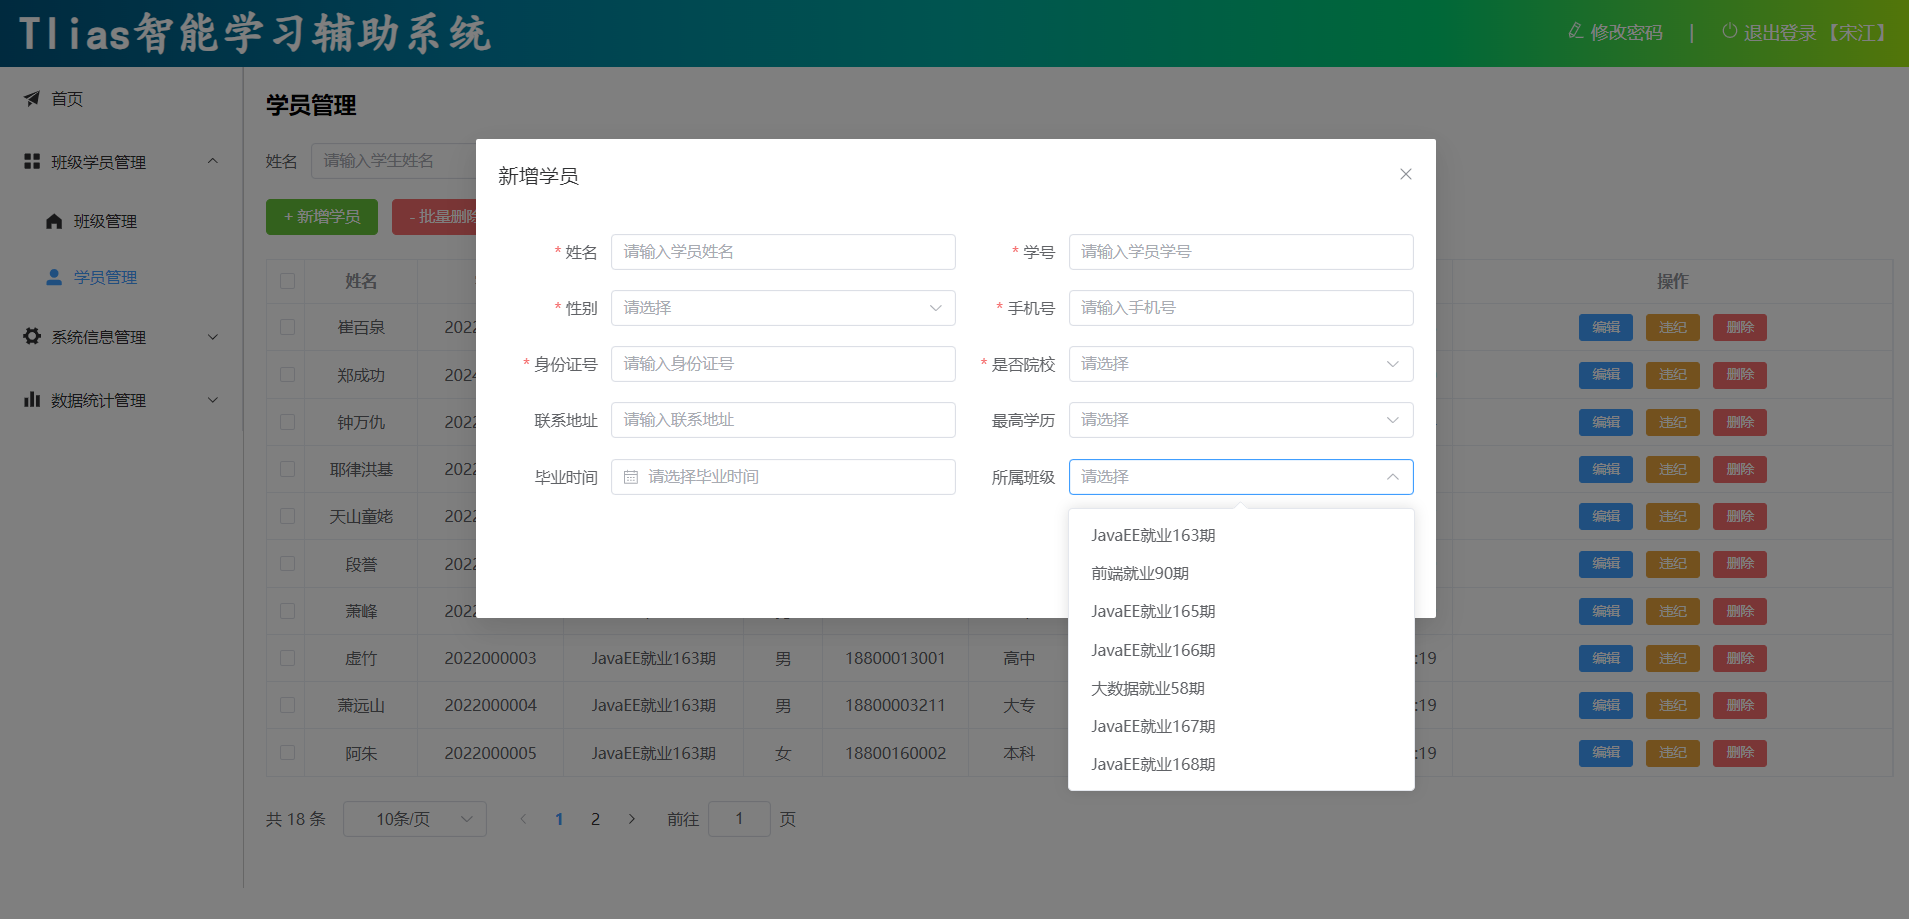


### 3.2 条件分页查询接口

参照接口文档 <strong><code>学员管理</code></strong> -&gt; <strong><code>学员列表查询</code></strong>

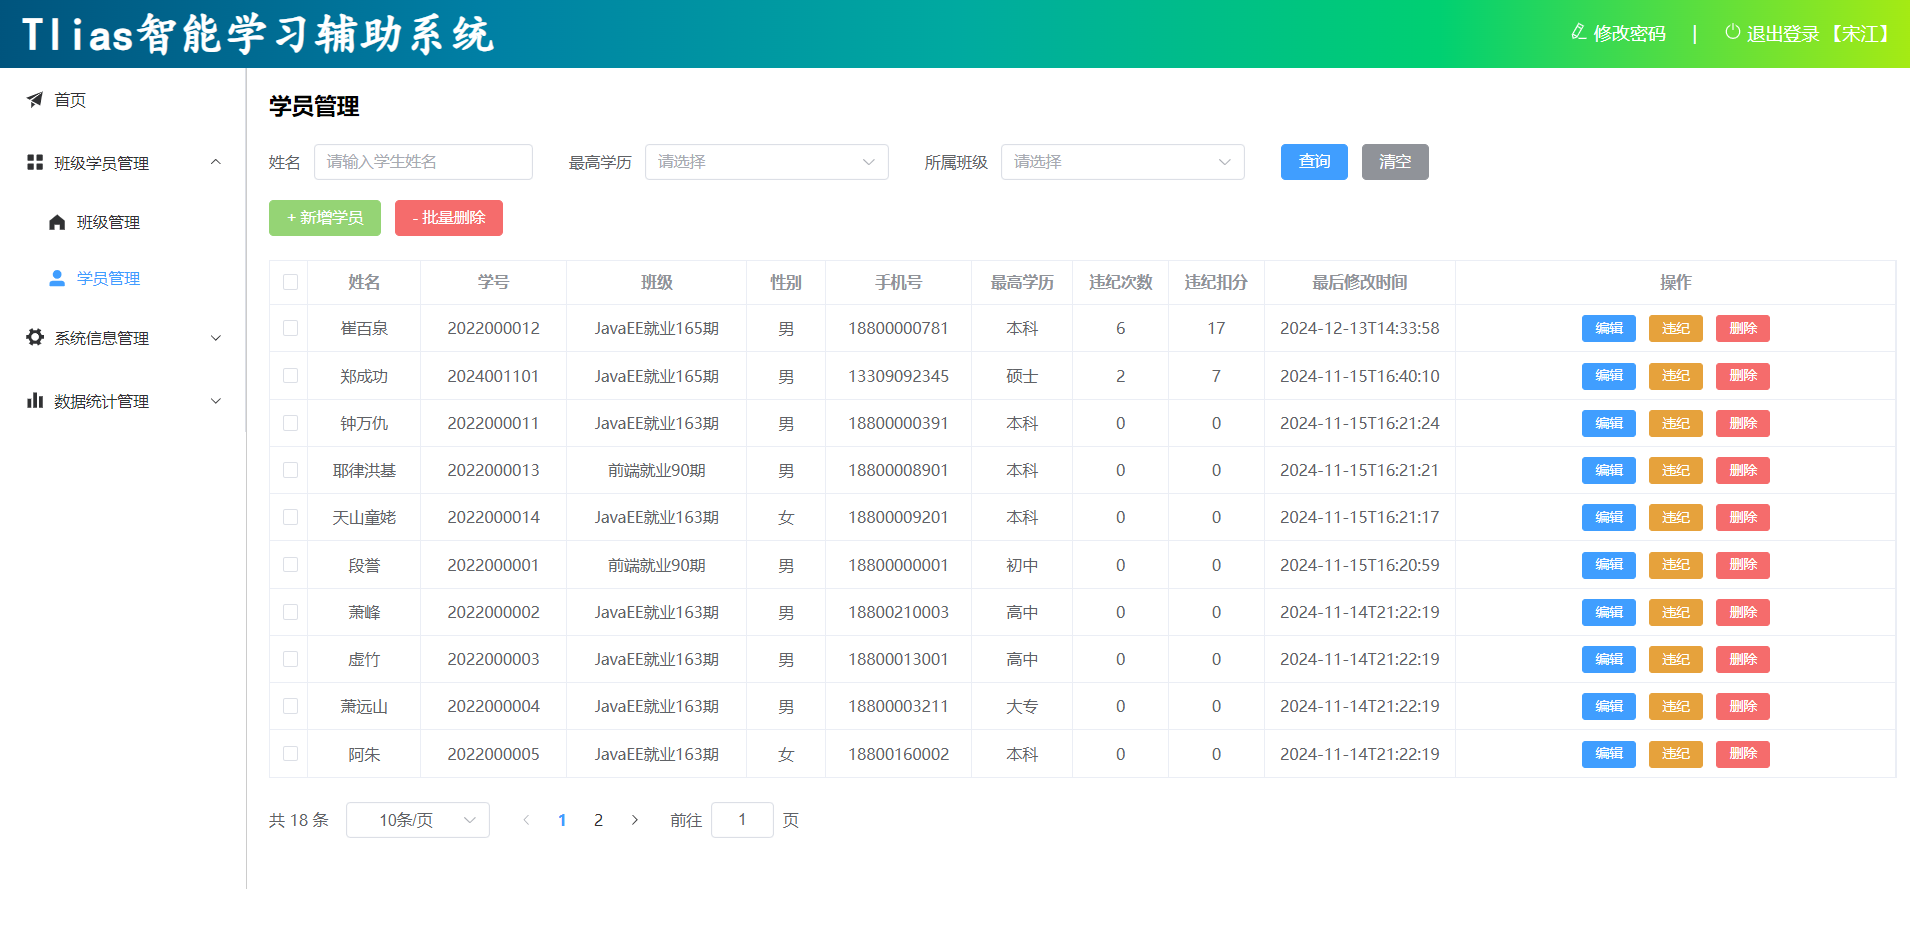


### 3.3 新增学生信息接口

参照接口文档 <strong><code>学员管理</code></strong> -&gt; <strong><code>添加学员</code></strong>

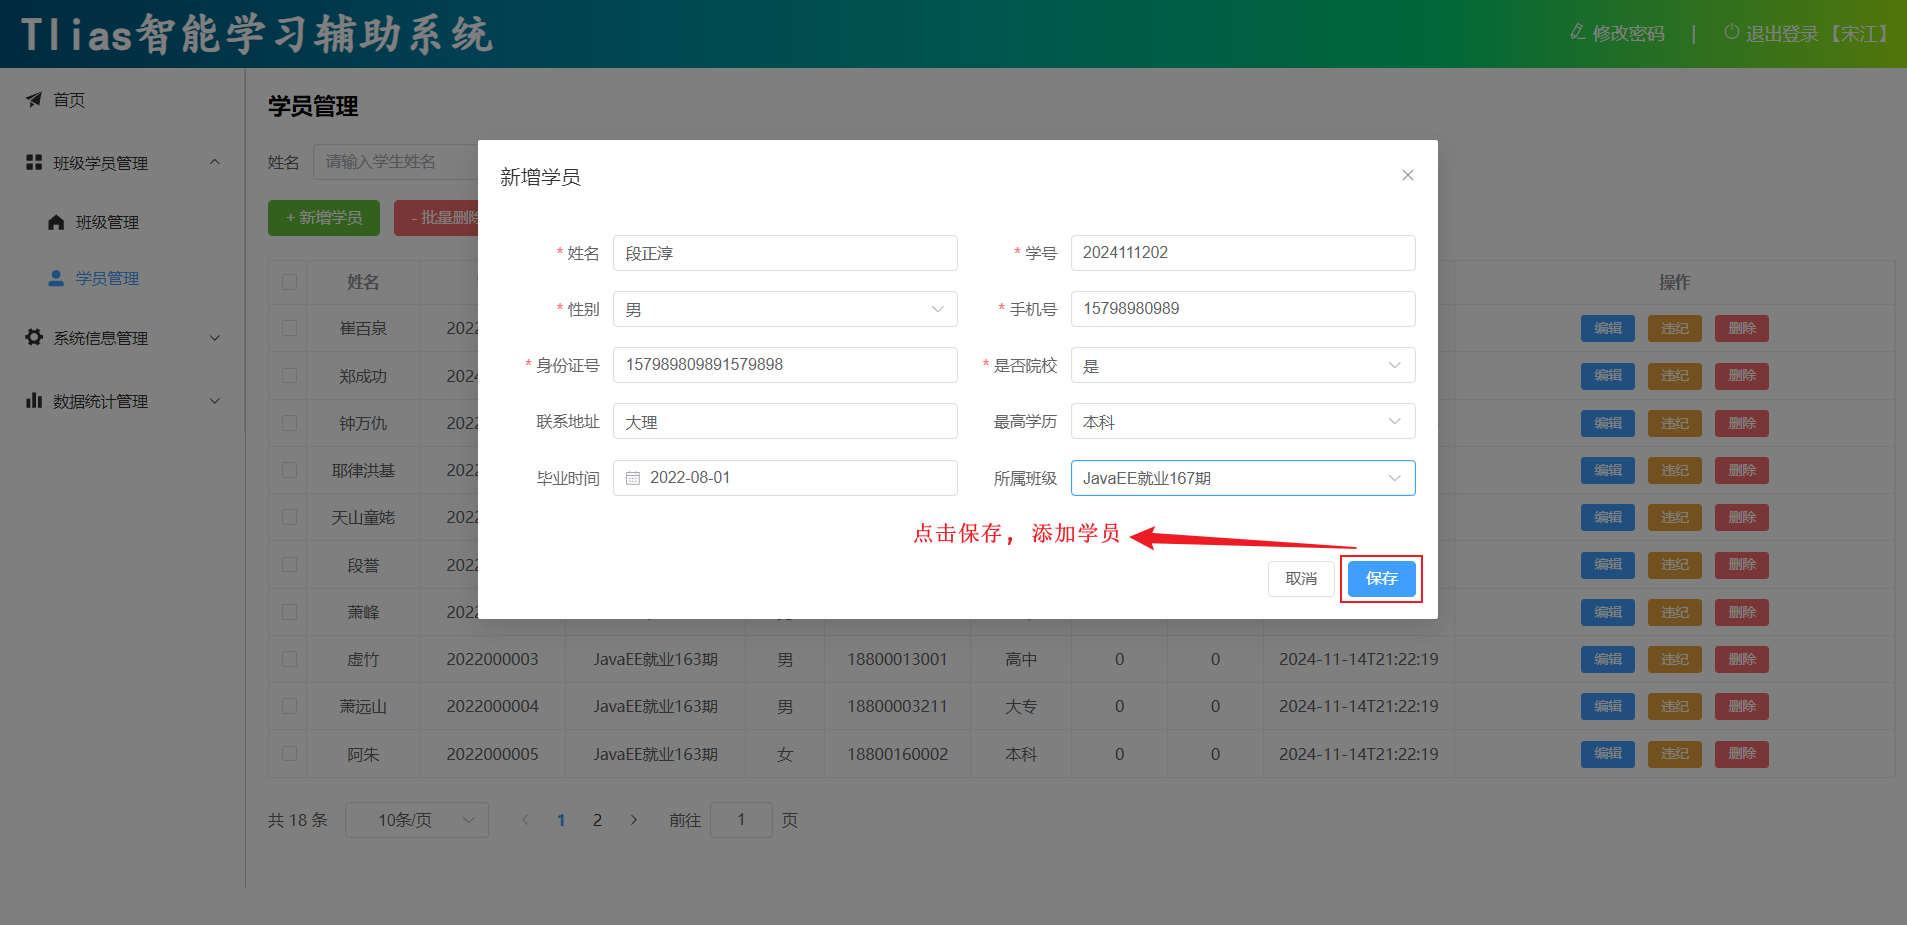


### 3.4 根据ID查询学生接口

参照接口文档 <strong><code>学员管理</code></strong> -&gt; <strong><code>根据ID查询学员</code></strong>

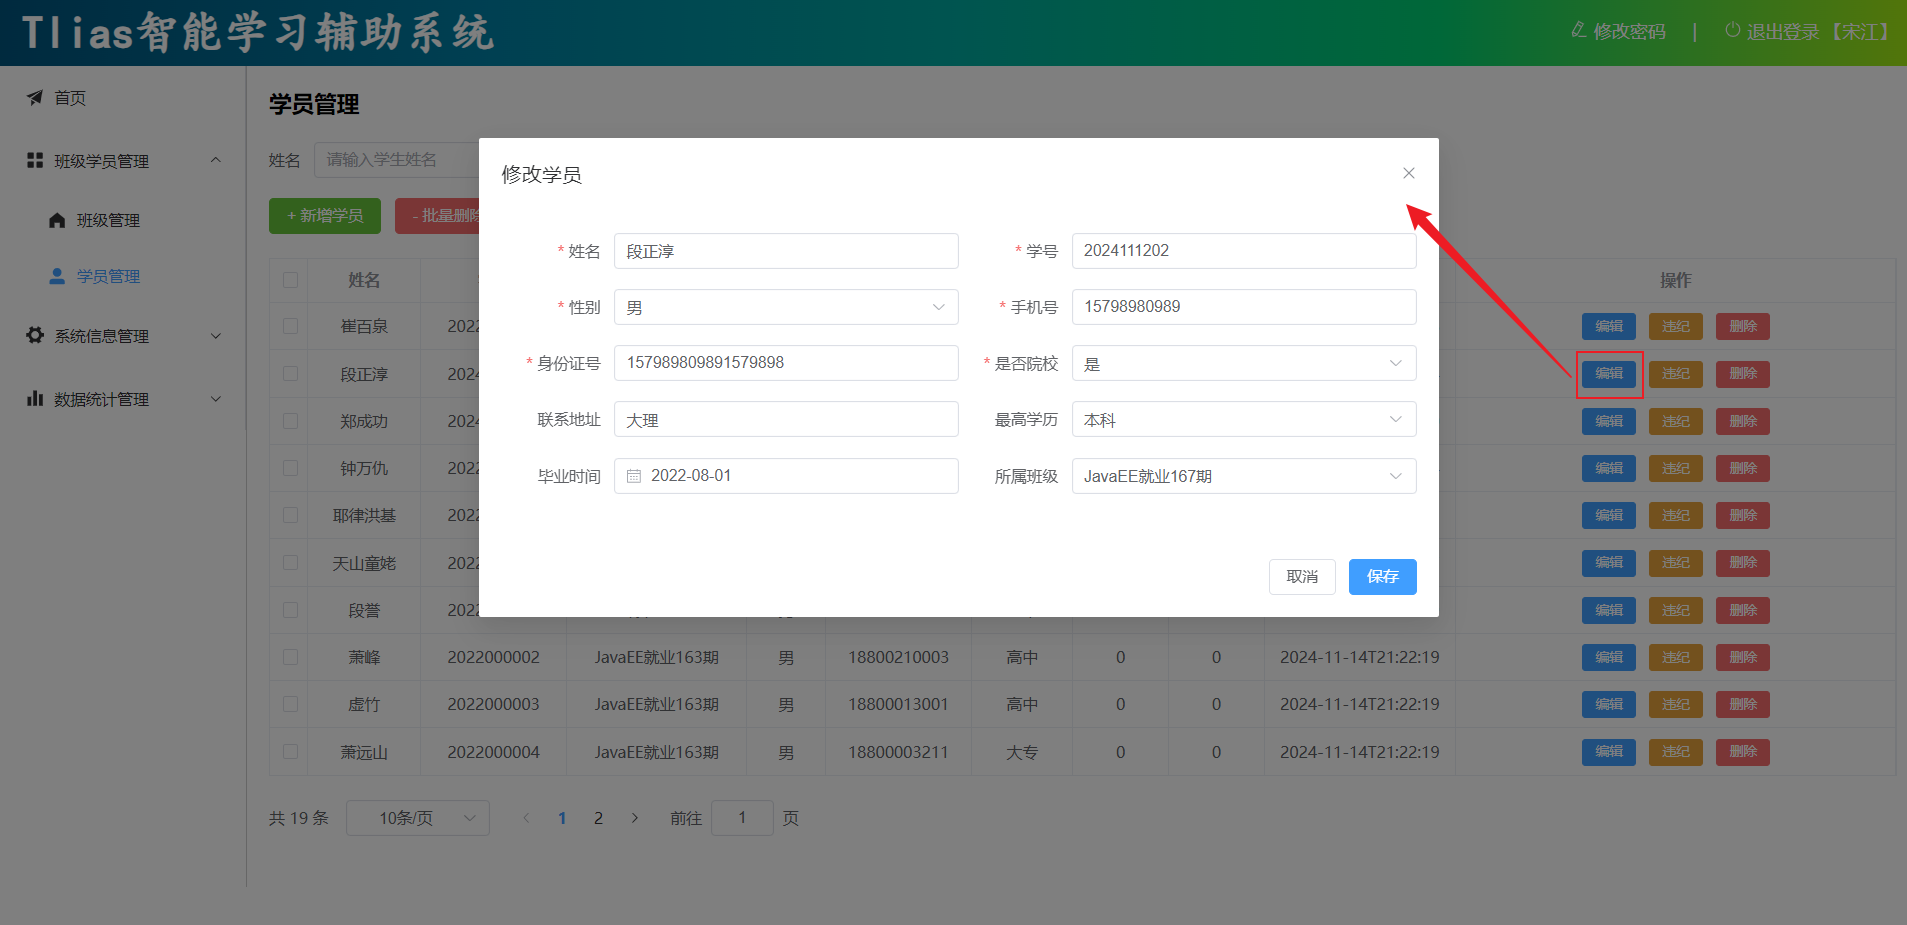


### 3.5 修改学生信息接口

参照接口文档 <strong><code>学员管理</code></strong> -&gt; <strong><code>修改学员</code></strong>

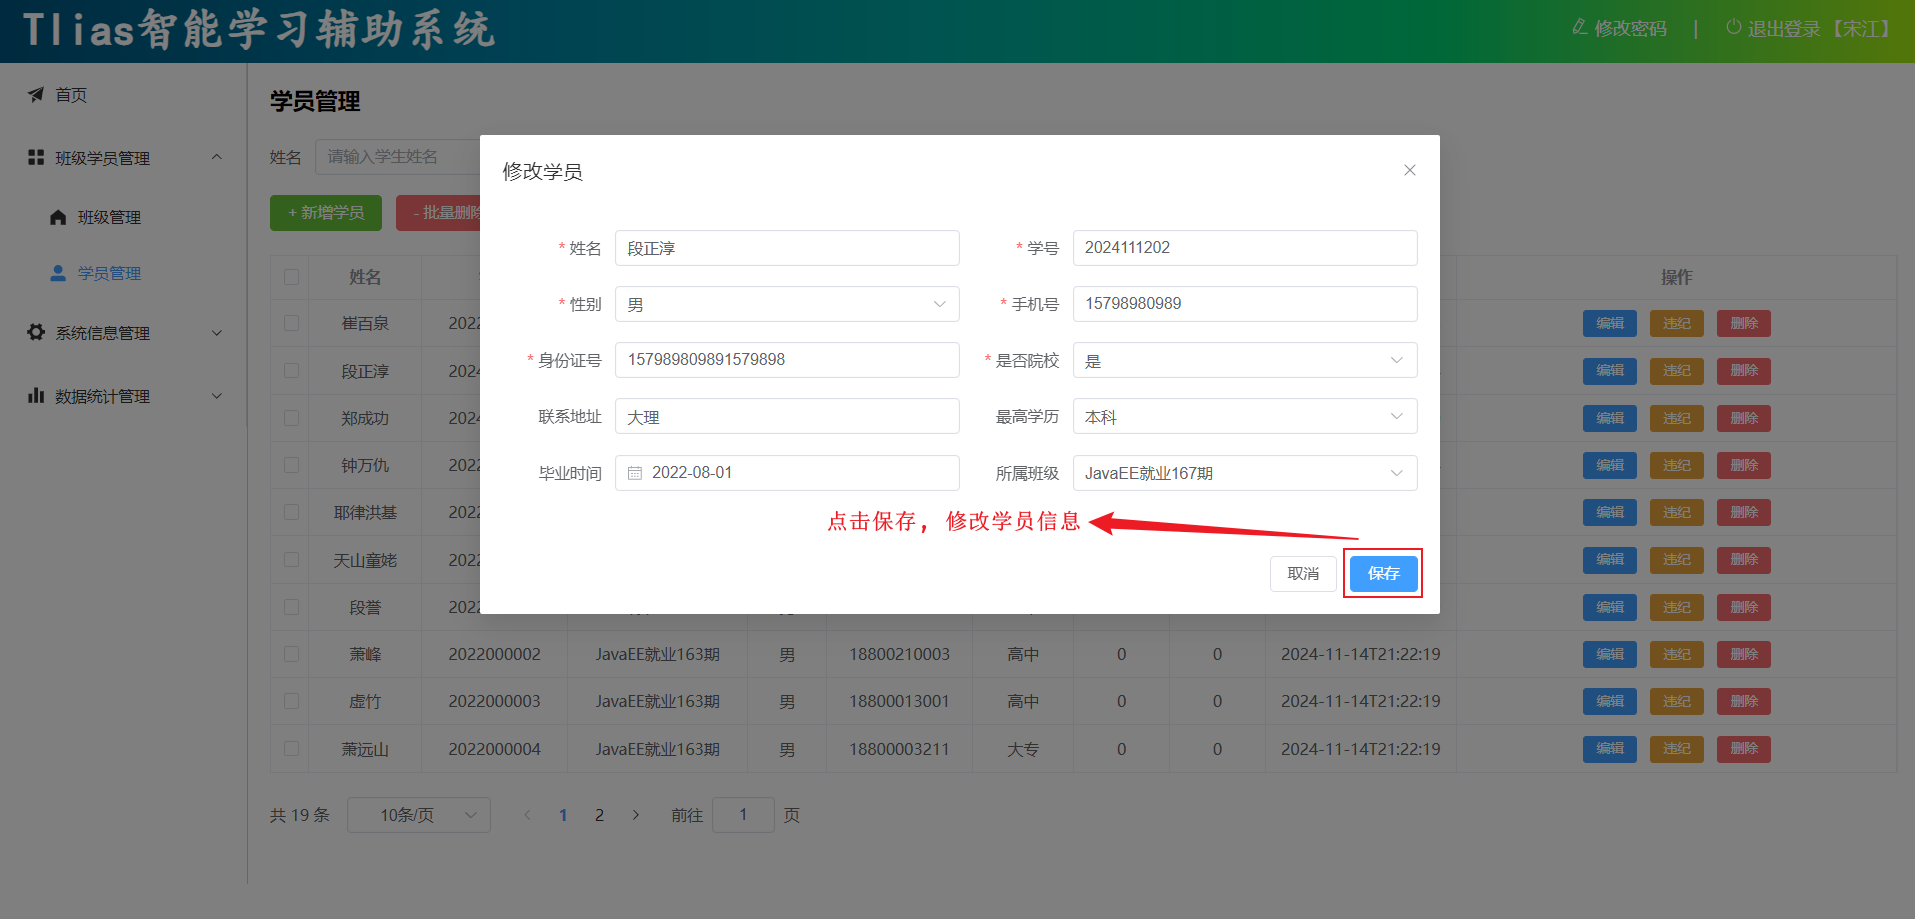


### 3.6 删除学生信息接口

参照接口文档 <strong><code>学员管理</code></strong> -&gt; <strong><code>删除学员</code></strong>

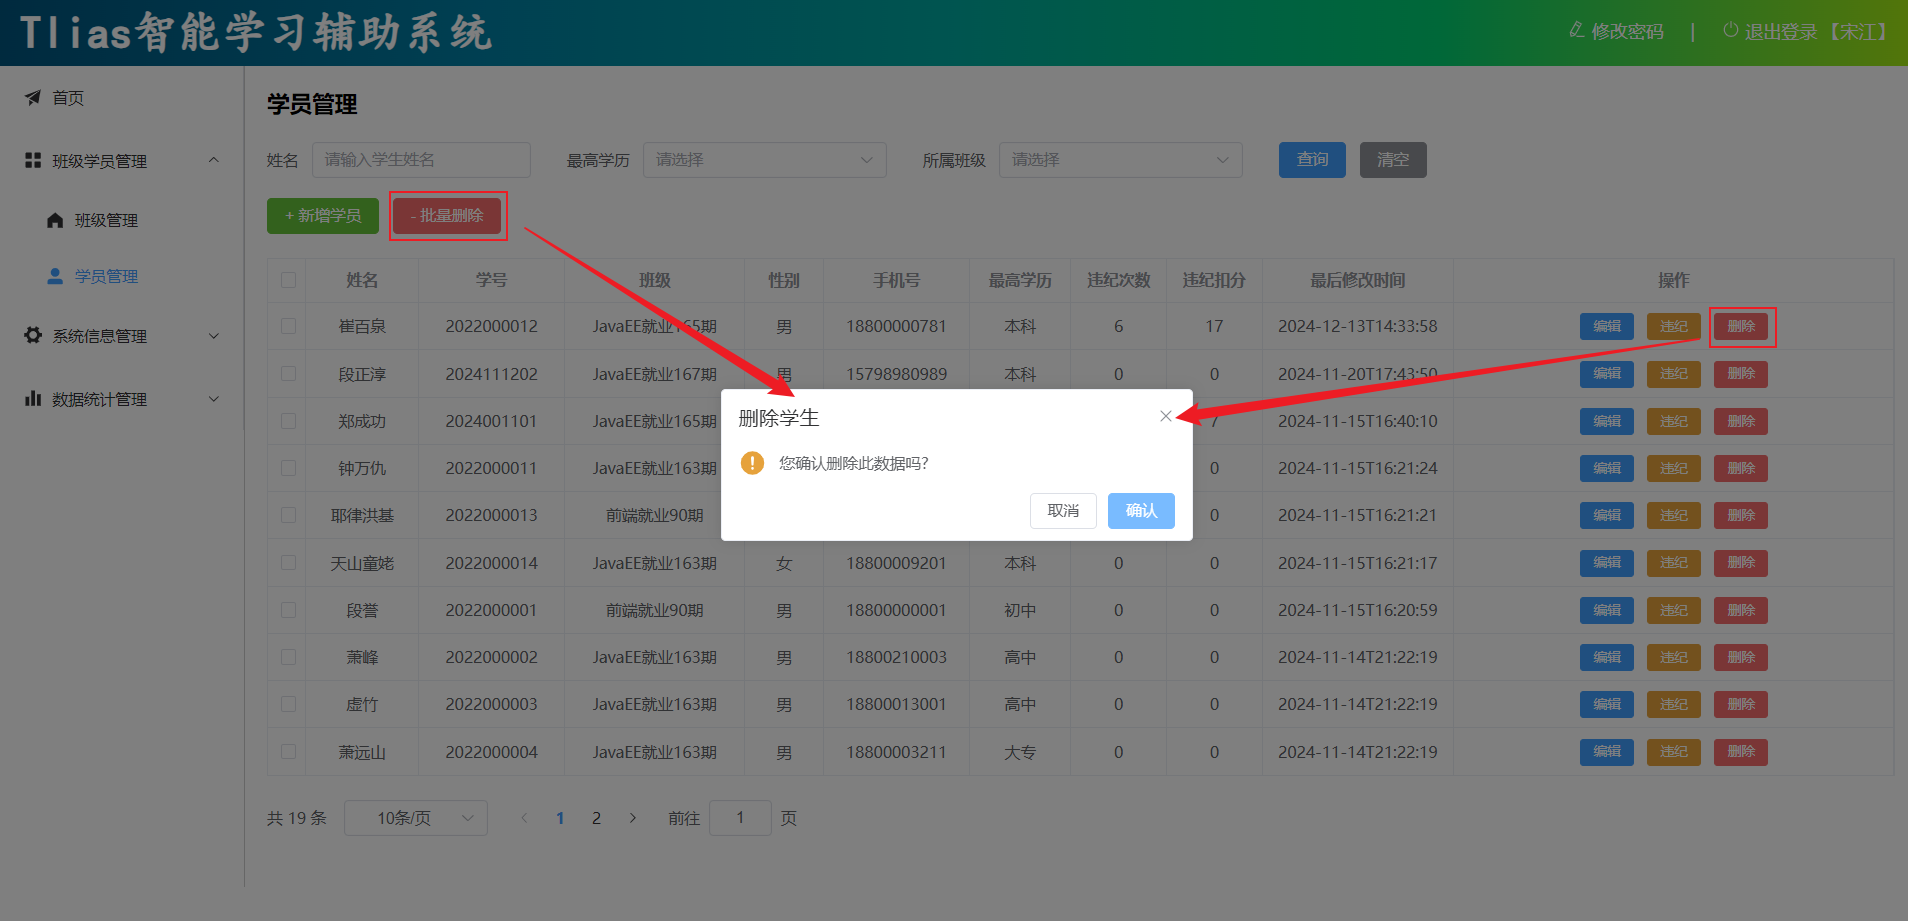


### 3.7 违纪处理接口

参照接口文档 <strong><code>学员管理</code></strong> -&gt; <strong><code>违纪处理</code></strong>

违纪处理一次，需要将违纪次数+1，违纪扣分+前端输入的分数。

**补充｜并发安全。** 违纪处理应使用一条原子更新 SQL：`violation_count = violation_count + 1`、`violation_score = violation_score + #{score}`，而不是先查再改。应校验 `score > 0`、学员存在，并考虑扣分上限及审计记录。

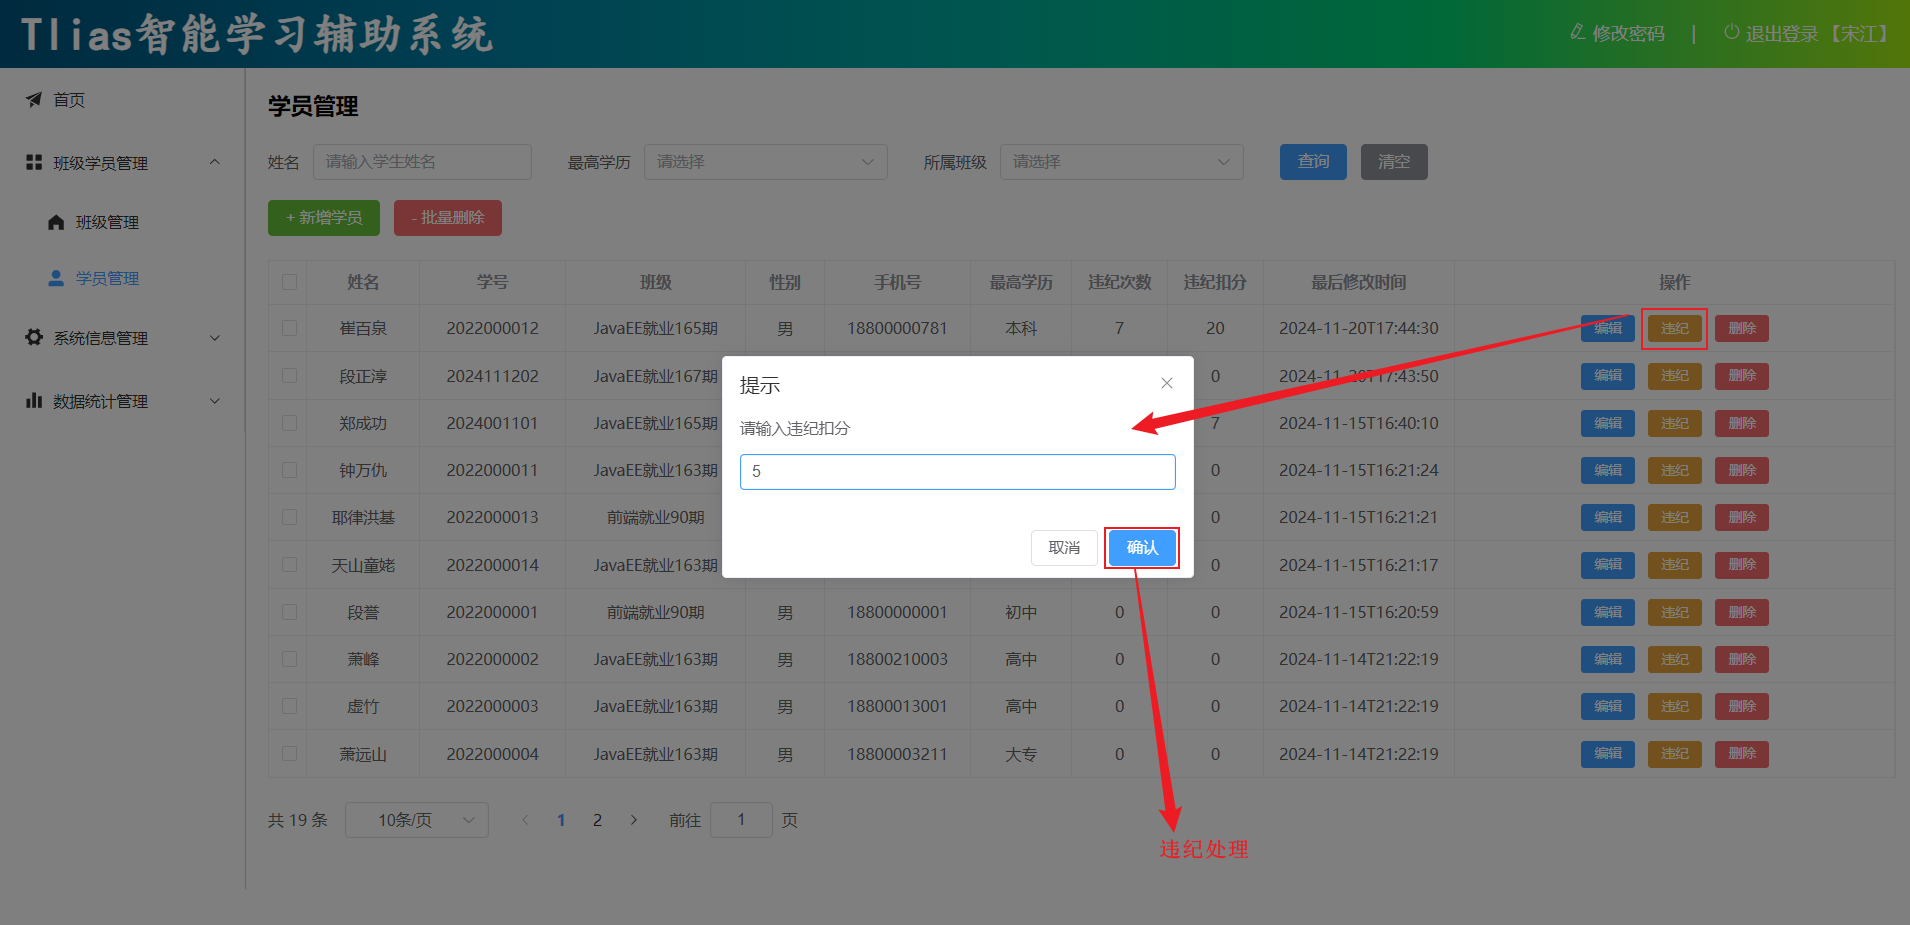

到此，关于学生管理的增删改查功能，我们就已经全部实现了。


## 4 需求：学员信息统计

需要开发如下几个接口：

- 班级人数统计接口开发：参照接口文档 <strong><code>数据统计</code></strong> -&gt; <strong><code>班级人数统计</code></strong>
- 学员学历信息统计接口开发：参照接口文档 <strong><code>数据统计</code></strong> -&gt; <strong><code>学员学历统计</code></strong>

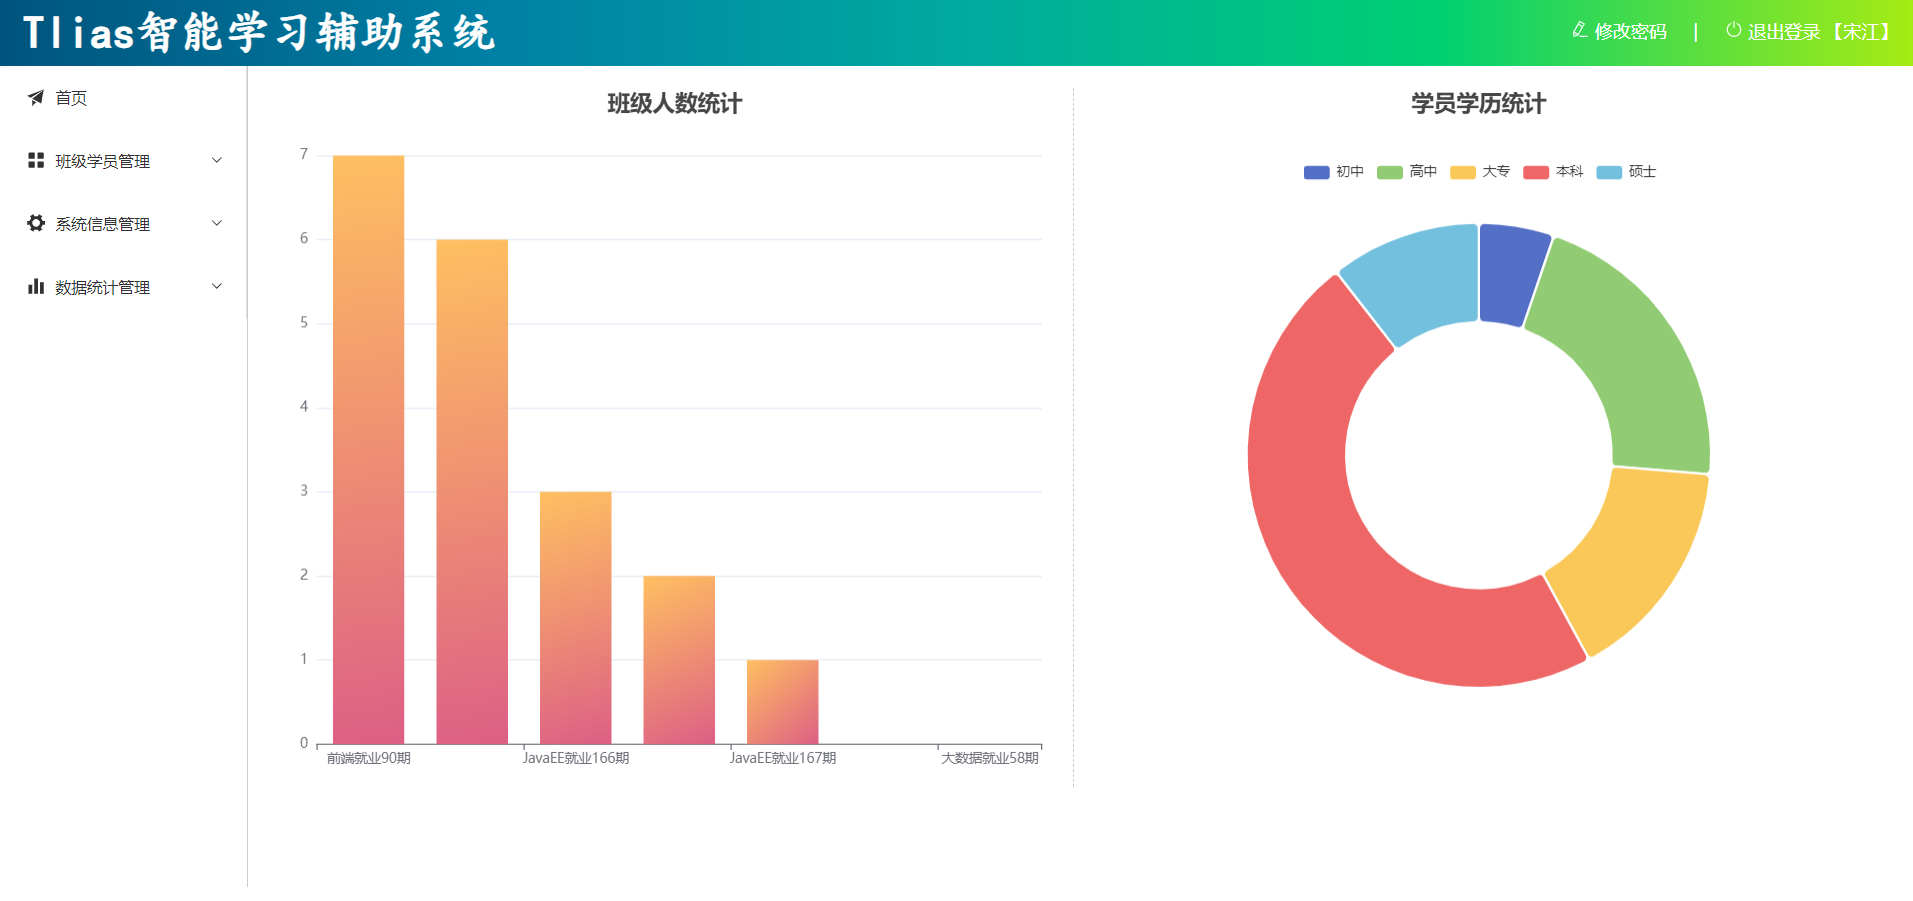


## 5 需求：功能完善

- <strong>删除部门时</strong><strong>：</strong>如果部门下有员工，则不允许删除该部门，并给前端提示错误信息：对不起，当前部门下有员工，不能直接删除！

**勘误｜功能对象。** 这里写的是“删除部门”，但本章练习的对应完善项应是“删除班级时，班级下有学员则不允许删除”。部门删除保护是第 07 章的同类规则。


## 6 补充：实现与验收清单

### 6.1 班级状态与关联

班级列表通常同时需要班级基本字段、班主任姓名和状态。`masterName` 可以来自员工关联查询；`status` 是由日期计算出的展示字段，不应当被当作持久化列写回 `clazz`。根据讲义的日期口径，状态表达式等价于：

```sql
case
  when current_date > end_date then '已结课'
  when current_date < begin_date then '未开班'
  else '在读中'
end
```

用查询条件筛选班级时，动态 SQL 应只拼接实际传入的条件。分页总数、当前页记录和排序规则必须与接口文档约定保持一致。

### 6.2 删除与违纪处理

删除班级前先判断是否存在关联学员，并用业务异常交给全局异常处理器。即使服务层先做检查，也建议在数据库层设置外键或其他约束，避免并发请求绕过业务判断。

```sql
update student
set violation_count = violation_count + 1,
    violation_score = violation_score + #{score},
    update_time = now()
where id = #{id};
```

上述更新影响行数为 0 时表示学员不存在；`score` 应在进入 Service 前完成正数校验。真实业务还应记录违纪原因、操作人和时间，而不是只保存累积值。

### 6.3 验收顺序

| 场景 | 应检查的结果 |
| --- | --- |
| 班级列表 | 状态、班主任名称、分页总数与日期边界一致 |
| 班级删除 | 空班级可删除；含学员的班级拒绝删除且数据不变 |
| 学员增改 | 学号、手机号、身份证号重复时返回统一业务错误 |
| 违纪处理 | 连续两次请求不会丢失次数或扣分 |
| 统计接口 | 零人数班级、未知学历和空数据的展示口径与前端一致 |

完成后再将请求参数、响应字段、错误信息逐项对照接口文档。接口文档是前后端联调的契约，代码内部设计不能改变其对外约定。
